# R4 – Neural networks (MLP and CNN)
**F20DL Group 5** · Requirement R4 
This notebook brings together all of the R4 work, which was originally written as Python scripts in `r4_neural_networks/`. The code below is the code from those scripts, organised into sections. Each section says which `.py` file it comes from.

| Section | What it covers | Original script(s) |
|---|---|---|
| 1 | Data, split checks and the feature-set versions | `mlp_keras.py`, `mlp_classifier_keras.py` |
| 2 | Regression MLP: tuning, validation, test, Figure 4 | `mlp_keras.py`, `plot_mlp.py` |
| 3 | Classification MLP: tuning, validation, test, Figure A1 | `mlp_classifier_keras.py`, `make_report_figures.py` |
| 4 | Comparison with the R3 models: Table 1, Appendix A.4, Figure A2 | `compare_r3.py`, `compare_by_feature_set.py`, `compare_r3_test.py`, `make_report_figures.py` |
| 5 | Album covers: matching, MSD-I visual features, CNN on raw covers (Appendix A.5) | `build_matched_features.py`, `download_covers.py`, `cover_features_keras.py`, `cnn_covers_keras.py` |



In [1]:
import os, sys, json, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error, mean_squared_error,
                             precision_recall_fscore_support, r2_score, recall_score,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.float_format", "{:.3f}".format)

RUN_TRAINING = False          # True = retrain the models (hours; needs TensorFlow/Keras)
OUT = "r4_neural_networks"     # where the R4 scripts saved their outputs
R3_DIR = "results"             # where the R3 notebooks saved theirs
def out(name): return os.path.join(OUT, name)

if RUN_TRAINING:
    os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
    import keras
    from keras import layers, regularizers
    from sklearn.utils.class_weight import compute_class_weight
    from sklearn.decomposition import PCA
print("RUN_TRAINING =", RUN_TRAINING)

RUN_TRAINING = False


## 1. Data, split checks and feature-set versions
*From `mlp_keras.py` and `mlp_classifier_keras.py`.*

The MLPs use the team's shared split in `spotgentrack_clean.csv`. `song_id` is used only for grouping, never as a feature. The feature-set versions are:

- `with_artist` / `all`: all 49 features
- `without_artist`: removes only `artist_popularity` and `log_followers` (47 columns, genres kept)
- `selected_3`: the team's feature selection (`selected_features.txt`): artist popularity, log followers and album type (5 encoded columns)
- `r3_no_artist`, `r3_audio`, `r3_metadata`: the feature groups defined by the R3 notebooks (`r3_common.feature_groups`)

In [2]:
SEED, N_FOLDS = 42, 10
N_CONFIGS = 6                    # settings tried per version (out of 36)
CLASSES = ["Low", "Medium", "High"]  # Low 0-40, Medium 41-60, High 61-100

df = pd.read_csv("spotgentrack_clean.csv")
df["split"] = df["split"].replace({"validation": "val"})
assert set(df["split"].unique()) == {"train", "val", "test"}, df["split"].unique()
assert "song_id" in df.columns, "re-download spotgentrack_clean.csv from GitHub"
assert set(df["pop_class"].unique()) == set(CLASSES), df["pop_class"].unique()

TARGET = "popularity"
DROP = ["id", "split", "popularity", "pop_class", "song_id"]   # song_id = grouping only
ALL_FEATURES = [c for c in df.columns if c not in DROP]
df["y"] = df["pop_class"].map({c: i for i, c in enumerate(CLASSES)}).astype(int)   # classification target

# ---- regression versions (mlp_keras.py) ----
ARTIST = ["artist_popularity", "log_followers"]
REG_VERSIONS = {"with_artist": ALL_FEATURES,
                "without_artist": [c for c in ALL_FEATURES if c not in ARTIST]}
SEL = [s.strip() for s in open("selected_features.txt").read().splitlines() if s.strip()]
REG_VERSIONS["selected_3"] = [c for c in ALL_FEATURES if c in SEL or any(c.startswith(s + "_") for s in SEL)]
import r3_common as rc                                    # feature sets as defined by the R3 notebooks
R3G = rc.feature_groups(df[[c for c in df.columns if c != "y"]])
for k in ("no_artist", "audio", "metadata"):
    REG_VERSIONS["r3_" + k] = [c for c in R3G[k] if c in ALL_FEATURES]

# ---- classification versions (mlp_classifier_keras.py) ----
CLF_VERSIONS = {"all": ALL_FEATURES}
for k in ("no_artist", "audio", "metadata"):
    CLF_VERSIONS["r3_" + k] = [c for c in R3G[k] if c in ALL_FEATURES]

print("selected_3 columns:", REG_VERSIONS["selected_3"])
print("regression versions:    ", {k: len(v) for k, v in REG_VERSIONS.items()})
print("classification versions:", {k: len(v) for k, v in CLF_VERSIONS.items()}, "(expect 49 / 34 / 26 / 23)")

train, val, test = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
print("train/val/test:", len(train), len(val), len(test))
assert not set(train.song_id) & set(val.song_id) and not set(train.song_id) & set(test.song_id) \
       and not set(val.song_id) & set(test.song_id), "a song appears in more than one split"
print("check passed: no song appears in more than one split")

selected_3 columns: ['artist_popularity', 'log_followers', 'album_type_album', 'album_type_compilation', 'album_type_single']
regression versions:     {'with_artist': 49, 'without_artist': 47, 'selected_3': 5, 'r3_no_artist': 34, 'r3_audio': 26, 'r3_metadata': 23}
classification versions: {'all': 49, 'r3_no_artist': 34, 'r3_audio': 26, 'r3_metadata': 23} (expect 49 / 34 / 26 / 23)
train/val/test: 71065 15237 15270
check passed: no song appears in more than one split


### The 6 settings tried (out of 36)
*From `mlp_keras.py` / `mlp_classifier_keras.py`.*

The grid has 3 layer sizes × 3 dropout rates × 2 learning rates × 2 L2 values = 36 combinations. Each combination needs 10 training runs (one per CV fold), so 6 were sampled at random with a fixed seed. Both MLPs use the same 6.

In [3]:
grid = [{"hidden": h, "dropout": d, "lr": lr, "l2": l2, "bs": 512}
        for h in [[64], [128, 64], [256, 128]] for d in [0.0, 0.2, 0.4]
        for lr in [1e-3, 3e-4] for l2 in [0.0, 1e-4]]
configs = random.Random(SEED).sample(grid, N_CONFIGS)
print(len(grid), "combinations in the grid;", len(configs), "sampled:")
pd.DataFrame([{**c, "hidden": str(c["hidden"]), "lr": f"{c['lr']:g}", "l2": f"{c['l2']:g}"} for c in configs])

36 combinations in the grid; 6 sampled:


,hidden,dropout,lr,l2,bs
0,[64],0.200,0.0003,0.0001,512
1,[64],0.000,0.001,0.0001,512
2,"[128, 64]",0.200,0.001,0.0001,512
3,"[128, 64]",0.000,0.0003,0.0001,512
4,"[128, 64]",0.000,0.0003,0,512
5,[64],0.200,0.001,0,512


In [4]:
# ---------- 10-fold stratified group CV on TRAIN (shared by both MLPs) ----------
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(train, train["pop_class"], groups=train["song_id"]))
print(len(folds), "folds; training rows per fold ≈", int(np.mean([len(a) for a, _ in folds])))

10 folds; training rows per fold ≈ 63958


## 2. Regression MLP
*From `mlp_keras.py`.*

Dense ReLU layers with optional dropout and L2, one linear output, Adam, MSE loss, batch size 512, up to 100 epochs. Early stopping (patience 10, best weights restored) monitors **validation** RMSE. The scaler and the target's mean/SD are fitted on the training rows only. Predictions are converted back to popularity points before scoring.

### 2.1 Model code

In [5]:
def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
def reg_metrics(a, b):
    return {"MAE": float(mean_absolute_error(a, b)), "RMSE": rmse(a, b), "R2": float(r2_score(a, b))}

def reg_prepare(feats, fit_df, *others):
    """Scaler and target stats are fitted on fit_df only (no leakage)."""
    cont = [c for c in feats if df[c].nunique() > 2]
    sc = StandardScaler().fit(fit_df[cont])
    def tx(d):
        X = d[feats].astype("float32").copy()
        X[cont] = sc.transform(d[cont]).astype("float32")
        return X.values
    return tx(fit_df), [tx(d) for d in others], fit_df[TARGET].mean(), fit_df[TARGET].std()

def reg_build_model(n_in, cfg):
    keras.utils.set_random_seed(SEED)
    reg = regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None
    m = keras.Sequential([keras.Input(shape=(n_in,))])
    for h in cfg["hidden"]:
        m.add(layers.Dense(h, activation="relu", kernel_regularizer=reg))
        if cfg["dropout"] > 0: m.add(layers.Dropout(cfg["dropout"]))
    m.add(layers.Dense(1))
    m.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss="mse",
              metrics=[keras.metrics.RootMeanSquaredError(name="rmse")])
    return m

def reg_fit_model(Xtr, ytr, Xva, yva_s, cfg):
    model = reg_build_model(Xtr.shape[1], cfg)
    es = keras.callbacks.EarlyStopping(monitor="val_rmse", mode="min", patience=10,
                                       restore_best_weights=True)
    model.fit(Xtr, ytr, validation_data=(Xva, yva_s), epochs=100,
              batch_size=cfg["bs"], callbacks=[es], verbose=0)
    return model

yva = val[TARGET].values

def reg_cv_score(feats, cfg):
    scores = []
    for tr_i, ho_i in folds:
        tr_df, ho_df = train.iloc[tr_i], train.iloc[ho_i]
        Xtr, (Xho, Xva), mu, sd = reg_prepare(feats, tr_df, ho_df, val)
        # early stopping uses the validation set (team protocol); the held-out fold is never seen
        model = reg_fit_model(Xtr, (tr_df[TARGET].values - mu) / sd, Xva, (yva - mu) / sd, cfg)
        p = model.predict(Xho, verbose=0).ravel() * sd + mu
        scores.append(rmse(ho_df[TARGET].values, p))
        keras.backend.clear_session()
    return float(np.mean(scores)), float(np.std(scores))

def reg_tune(name):
    path = out(f"mlp_best_{name}.json")            # delete this file to redo the search
    if os.path.exists(path):
        return json.load(open(path))["cfg"]
    rows = []
    for k, cfg in enumerate(configs, 1):
        m, s = reg_cv_score(REG_VERSIONS[name], cfg)
        rows.append({**cfg, "hidden": str(cfg["hidden"]), "cv_rmse": m, "cv_sd": s})
        print(f"[{name}] {k}/{N_CONFIGS} {cfg} -> CV RMSE {m:.3f} ± {s:.3f}")
    pd.DataFrame(rows).sort_values("cv_rmse").to_csv(out(f"mlp_cv_{name}.csv"), index=False)
    best = configs[int(np.argmin([r["cv_rmse"] for r in rows]))]
    json.dump({"cfg": best}, open(path, "w"))
    return best

def reg_final_fit(name, cfg, include_test):
    """Refit on the full train set, early stop on validation."""
    Xtr, others, mu, sd = reg_prepare(REG_VERSIONS[name], train, val, *([test] if include_test else []))
    model = reg_fit_model(Xtr, (train[TARGET].values - mu) / sd, others[0], (yva - mu) / sd, cfg)
    pred = lambda X: model.predict(X, verbose=0).ravel() * sd + mu
    return pred(others[0]), (pred(others[1]) if include_test else None)

### 2.2 Training: tuning, validation and the final test
Only runs when `RUN_TRAINING = True`. `reg_tune` reuses a saved `mlp_best_<version>.json` if it exists.

In [6]:
REG_RUN = ["with_artist", "without_artist", "selected_3", "r3_no_artist", "r3_audio", "r3_metadata"]
RUN_TEST_REG = False

if RUN_TRAINING:
    if not RUN_TEST_REG:
        res = [{"model": "mean_baseline", **reg_metrics(yva, np.full(len(val), train[TARGET].mean()))}]
        for name in REG_RUN:
            cfg = reg_tune(name)
            pv, _ = reg_final_fit(name, cfg, include_test=False)
            res.append({"model": f"mlp_{name}", **reg_metrics(yva, pv)})
            pd.DataFrame({"id": val["id"], "y_true": yva, "y_pred": pv}).to_csv(
                out(f"mlp_val_predictions_{name}.csv"), index=False)
        print(pd.DataFrame(res).to_string(index=False))
    else:
        yte = test[TARGET].values
        all_res = {"mean_baseline_test": reg_metrics(yte, np.full(len(test), train[TARGET].mean()))}
        for name in REG_RUN:
            cfg = reg_tune(name)                      # loads the saved best settings, no new search
            _, pt = reg_final_fit(name, cfg, include_test=True)
            all_res[f"mlp_{name}_test"] = {"config": cfg, **reg_metrics(yte, pt)}
            pd.DataFrame({"id": test["id"], "y_true": yte, "y_pred": pt}).to_csv(
                out(f"mlp_test_predictions_{name}.csv"), index=False)
        print(json.dumps(all_res, indent=2))
else:
    print("RUN_TRAINING is False: skipped. The saved results are loaded below.")

RUN_TRAINING is False: skipped. The saved results are loaded below.


### 2.3 Results: selected settings and CV (Appendix A.2)
Loaded from `mlp_best_<version>.json` and `mlp_cv_<version>.csv`. The range column shows how much the 6 settings differed.

In [7]:
rows = []
for name in REG_RUN:
    cfg = json.load(open(out(f"mlp_best_{name}.json")))["cfg"]
    cvt = pd.read_csv(out(f"mlp_cv_{name}.csv"))
    rows.append({"version": name, "columns": len(REG_VERSIONS[name]), "hidden": str(cfg["hidden"]),
                 "dropout": cfg["dropout"], "lr": f"{cfg['lr']:g}", "l2": f"{cfg['l2']:g}",
                 "best CV RMSE": cvt["cv_rmse"].min(), "CV RMSE range": f"{cvt['cv_rmse'].min():.2f} – {cvt['cv_rmse'].max():.2f}",
                 "fold SD": cvt.loc[cvt["cv_rmse"].idxmin(), "cv_sd"]})
pd.DataFrame(rows)

,version,columns,hidden,dropout,lr,l2,best CV RMSE,CV RMSE range,fold SD
0,with_artist,49,"[128, 64]",0.200,0.001,0.0001,9.746,9.75 – 9.90,0.099
1,without_artist,47,"[128, 64]",0.200,0.001,0.0001,13.149,13.15 – 13.29,0.106
2,selected_3,5,"[128, 64]",0.000,0.0003,0,10.972,10.97 – 11.12,0.112
3,r3_no_artist,34,"[128, 64]",0.200,0.001,0.0001,14.093,14.09 – 14.26,0.111
4,r3_audio,26,"[128, 64]",0.200,0.001,0.0001,14.789,14.79 – 14.88,0.082
5,r3_metadata,23,"[128, 64]",0.200,0.001,0.0001,9.838,9.84 – 10.15,0.117


In [8]:
# all 6 settings for the main version (all features)
cv_all = pd.read_csv(out("mlp_cv_with_artist.csv"))
cv_all[["lr", "l2"]] = cv_all[["lr", "l2"]].map(lambda x: f"{x:g}")
cv_all

,hidden,dropout,lr,l2,bs,cv_rmse,cv_sd
0,"[128, 64]",0.200,0.001,0.0001,512,9.746,0.099
1,[64],0.200,0.001,0,512,9.837,0.105
2,"[128, 64]",0.000,0.0003,0.0001,512,9.872,0.099
3,[64],0.200,0.0003,0.0001,512,9.884,0.106
4,[64],0.000,0.001,0.0001,512,9.888,0.096
5,"[128, 64]",0.000,0.0003,0,512,9.898,0.094


### 2.4 Results: validation and test (Appendix A.2)
Recomputed from the saved prediction files (`mlp_val_predictions_*.csv`, `mlp_test_predictions_*.csv`).

In [9]:
ytr_mean = train[TARGET].mean()
rows = [{"version": "mean baseline",
         **{f"val {k}": v for k, v in reg_metrics(val[TARGET], np.full(len(val), ytr_mean)).items()},
         **{f"test {k}": v for k, v in reg_metrics(test[TARGET], np.full(len(test), ytr_mean)).items()}}]
for name in ["with_artist", "r3_metadata", "selected_3", "without_artist", "r3_no_artist", "r3_audio"]:
    v = pd.read_csv(out(f"mlp_val_predictions_{name}.csv"))
    t = pd.read_csv(out(f"mlp_test_predictions_{name}.csv"))
    rows.append({"version": f"{name} ({len(REG_VERSIONS[name])})",
                 **{f"val {k}": x for k, x in reg_metrics(v.y_true, v.y_pred).items()},
                 **{f"test {k}": x for k, x in reg_metrics(t.y_true, t.y_pred).items()}})
reg_table = pd.DataFrame(rows)
reg_table

,version,val MAE,val RMSE,val R2,test MAE,test RMSE,test R2
0,mean baseline,13.503,16.741,-0.000,13.412,16.699,-0.000
1,with_artist (49),7.498,9.697,0.664,7.465,9.621,0.668
2,r3_metadata (23),7.622,9.823,0.656,7.585,9.763,0.658
3,selected_3 (5),8.663,11.057,0.564,8.609,10.990,0.567
4,without_artist (47),10.374,13.059,0.391,10.274,12.940,0.400
5,r3_no_artist (34),11.191,14.030,0.298,11.035,13.878,0.309
6,r3_audio (26),11.827,14.750,0.224,11.683,14.615,0.234


### 2.5 Figure 4: predicted vs actual popularity (test set)
*From `plot_mlp.py`.* Saved as `r4_neural_networks/mlp_pred_vs_actual.png`.

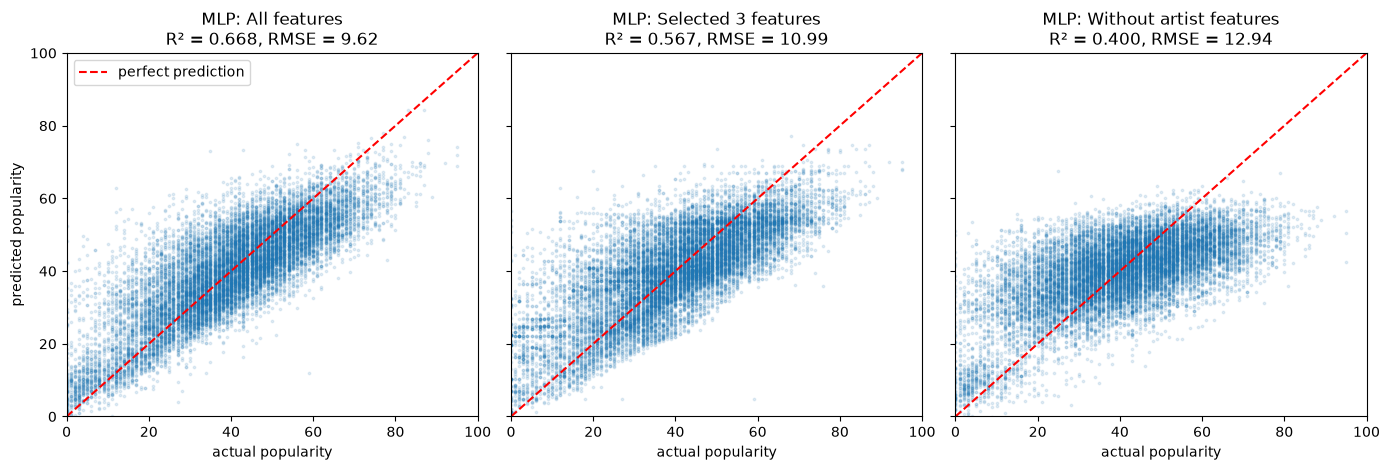

In [10]:
panels = [("with_artist", "All features"),
          ("selected_3", "Selected 3 features"),
          ("without_artist", "Without artist features")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharex=True, sharey=True)
for ax, (name, title) in zip(axes, panels):
    d = pd.read_csv(out(f"mlp_test_predictions_{name}.csv"))
    r2 = r2_score(d.y_true, d.y_pred)
    rm = mean_squared_error(d.y_true, d.y_pred) ** 0.5
    ax.scatter(d.y_true, d.y_pred, s=3, alpha=0.12)
    ax.plot([0, 100], [0, 100], "r--", label="perfect prediction")
    ax.set_title(f"MLP: {title}\nR² = {r2:.3f}, RMSE = {rm:.2f}")
    ax.set_xlabel("actual popularity")
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
axes[0].set_ylabel("predicted popularity")
axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

## 3. Classification MLP
*From `mlp_classifier_keras.py`.*

Same pipeline with a three-class softmax output (Low 0–40, Medium 41–60, High 61–100), cross-entropy loss and balanced class weights, because only 10.7% of tracks are High. Early stopping and model selection use **validation macro-F1** (patience 10, best weights restored), matching the R3 classifiers.

### 3.1 Model code

In [11]:
def clf_metrics(y, p):
    pr, rc_, f1, _ = precision_recall_fscore_support(y, p, labels=[0, 1, 2], zero_division=0)
    o = {"accuracy": float(accuracy_score(y, p)), "macro_F1": float(f1.mean()),
         "weighted_F1": float(f1_score(y, p, average="weighted", zero_division=0))}
    for i, c in enumerate(CLASSES):
        o[f"{c}_precision"], o[f"{c}_recall"], o[f"{c}_F1"] = float(pr[i]), float(rc_[i]), float(f1[i])
    return o

def clf_prepare(feats, fit_df, *others):
    """The scaler is fitted on fit_df only (no leakage)."""
    cont = [c for c in feats if df[c].nunique() > 2]
    sc = StandardScaler().fit(fit_df[cont])
    def tx(d):
        X = d[feats].astype("float32").copy()
        X[cont] = sc.transform(d[cont]).astype("float32")
        return X.values
    return tx(fit_df), [tx(d) for d in others]

def clf_build_model(n_in, cfg):
    keras.utils.set_random_seed(SEED)
    reg = regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None
    m = keras.Sequential([keras.Input(shape=(n_in,))])
    for h in cfg["hidden"]:
        m.add(layers.Dense(h, activation="relu", kernel_regularizer=reg))
        if cfg["dropout"] > 0: m.add(layers.Dropout(cfg["dropout"]))
    m.add(layers.Dense(3, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss="sparse_categorical_crossentropy")
    return m

if RUN_TRAINING:
    class MacroF1Stop(keras.callbacks.Callback):
        """Early stopping on the validation set's macro-F1; the best weights are restored at the end."""
        def __init__(self, Xva, yva, patience=10):
            super().__init__(); self.Xva, self.yva, self.patience = Xva, yva, patience
        def on_train_begin(self, logs=None):
            self.best, self.wait, self.best_w = -1.0, 0, None
        def on_epoch_end(self, epoch, logs=None):
            p = self.model.predict(self.Xva, batch_size=4096, verbose=0).argmax(1)
            f = f1_score(self.yva, p, average="macro")
            if f > self.best + 1e-4:
                self.best, self.wait, self.best_w = f, 0, self.model.get_weights()
            else:
                self.wait += 1
                if self.wait >= self.patience: self.model.stop_training = True
        def on_train_end(self, logs=None):
            if self.best_w is not None: self.model.set_weights(self.best_w)

def clf_fit_model(Xtr, ytr, Xva, yva_, cfg):
    cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(3), y=ytr)))
    model = clf_build_model(Xtr.shape[1], cfg)
    model.fit(Xtr, ytr, epochs=100, batch_size=cfg["bs"], class_weight=cw,
              callbacks=[MacroF1Stop(Xva, yva_)], verbose=0)
    return model

def clf_predict(model, X):
    return model.predict(X, batch_size=4096, verbose=0).argmax(1)

yva_c = val["y"].values

def clf_cv_score(feats, cfg):
    scores = []
    for tr_i, ho_i in folds:
        tr_df, ho_df = train.iloc[tr_i], train.iloc[ho_i]
        Xtr, (Xho, Xva) = clf_prepare(feats, tr_df, ho_df, val)
        # early stopping uses the validation set (team protocol); the held-out fold is never seen
        model = clf_fit_model(Xtr, tr_df["y"].values, Xva, yva_c, cfg)
        scores.append(f1_score(ho_df["y"].values, clf_predict(model, Xho), average="macro"))
        keras.backend.clear_session()
    return float(np.mean(scores)), float(np.std(scores))

def clf_tune(name):
    path = out(f"mlpclf_best_{name}.json")          # delete this file to redo the search
    if os.path.exists(path):
        return json.load(open(path))["cfg"]
    rows = []
    for k, cfg in enumerate(configs, 1):
        m, s = clf_cv_score(CLF_VERSIONS[name], cfg)
        rows.append({**cfg, "hidden": str(cfg["hidden"]), "cv_macro_F1": m, "cv_sd": s})
        print(f"[{name}] {k}/{N_CONFIGS} {cfg} -> CV macro-F1 {m:.3f} ± {s:.3f}", flush=True)
    pd.DataFrame(rows).sort_values("cv_macro_F1", ascending=False).to_csv(out(f"mlpclf_cv_{name}.csv"), index=False)
    best = configs[int(np.argmax([r["cv_macro_F1"] for r in rows]))]
    json.dump({"cfg": best}, open(path, "w"))
    return best

def clf_final_fit(name, cfg, include_test):
    """Refit on the full train set, early stop on validation."""
    Xtr, others = clf_prepare(CLF_VERSIONS[name], train, val, *([test] if include_test else []))
    model = clf_fit_model(Xtr, train["y"].values, others[0], yva_c, cfg)
    return clf_predict(model, others[0]), (clf_predict(model, others[1]) if include_test else None)

### 3.2 Training: tuning, validation and the final test
Only runs when `RUN_TRAINING = True`.

In [12]:
CLF_RUN = ["all", "r3_no_artist", "r3_audio", "r3_metadata"]
RUN_TEST_CLF = False
majority = int(train["y"].value_counts().idxmax())

if RUN_TRAINING:
    if not RUN_TEST_CLF:
        res = [{"model": "majority_baseline", **clf_metrics(yva_c, np.full(len(val), majority))}]
        for name in CLF_RUN:
            cfg = clf_tune(name)
            pv, _ = clf_final_fit(name, cfg, include_test=False)
            res.append({"model": f"mlp_clf_{name}", **clf_metrics(yva_c, pv)})
            pd.DataFrame({"id": val["id"], "y_true": [CLASSES[i] for i in yva_c],
                          "y_pred": [CLASSES[i] for i in pv]}).to_csv(
                out(f"mlpclf_val_predictions_{name}.csv"), index=False)
        print(pd.DataFrame(res).to_string(index=False))
    else:
        yte_c = test["y"].values
        all_res = {"majority_baseline_test": clf_metrics(yte_c, np.full(len(test), majority))}
        for name in CLF_RUN:
            cfg = clf_tune(name)                      # loads the saved best settings, no new search
            _, pt = clf_final_fit(name, cfg, include_test=True)
            all_res[f"mlp_clf_{name}_test"] = {"config": cfg, **clf_metrics(yte_c, pt)}
            pd.DataFrame({"id": test["id"], "y_true": [CLASSES[i] for i in yte_c],
                          "y_pred": [CLASSES[i] for i in pt]}).to_csv(
                out(f"mlpclf_test_predictions_{name}.csv"), index=False)
        print(json.dumps(all_res, indent=2))
else:
    print("RUN_TRAINING is False: skipped. The saved results are loaded below.")

RUN_TRAINING is False: skipped. The saved results are loaded below.


### 3.3 Results: selected settings and CV (Appendix A.3)

In [13]:
rows = []
for name in CLF_RUN:
    cfg = json.load(open(out(f"mlpclf_best_{name}.json")))["cfg"]
    cvt = pd.read_csv(out(f"mlpclf_cv_{name}.csv"))
    rows.append({"version": name, "columns": len(CLF_VERSIONS[name]), "hidden": str(cfg["hidden"]),
                 "dropout": cfg["dropout"], "lr": f"{cfg['lr']:g}", "l2": f"{cfg['l2']:g}",
                 "best CV macro-F1": cvt["cv_macro_F1"].max(),
                 "CV macro-F1 range": f"{cvt['cv_macro_F1'].min():.3f} – {cvt['cv_macro_F1'].max():.3f}"})
pd.DataFrame(rows)

,version,columns,hidden,dropout,lr,l2,best CV macro-F1,CV macro-F1 range
0,all,49,"[128, 64]",0.200,0.001,0.0001,0.631,0.622 – 0.631
1,r3_no_artist,34,"[128, 64]",0.000,0.0003,0,0.438,0.421 – 0.438
2,r3_audio,26,"[128, 64]",0.000,0.0003,0.0001,0.396,0.383 – 0.396
3,r3_metadata,23,"[128, 64]",0.000,0.0003,0.0001,0.627,0.616 – 0.627


### 3.4 Results: validation and test (Appendix A.3)
Recomputed from `mlpclf_val_predictions_*.csv` and `mlpclf_test_predictions_*.csv`.

In [14]:
def clf_from_file(path):
    d = pd.read_csv(path)
    to_i = {c: i for i, c in enumerate(CLASSES)}
    return clf_metrics(d["y_true"].map(to_i).values, d["y_pred"].map(to_i).values)

order = [("all", "all"), ("r3_metadata", "metadata"), ("r3_no_artist", "no artist (R3)"), ("r3_audio", "audio")]
cols = ["accuracy", "macro_F1", "Low_F1", "Medium_F1", "High_F1", "High_recall"]
val_rows = [{"version": "majority class", **clf_metrics(yva_c, np.full(len(val), majority))}]
val_rows += [{"version": lab, **clf_from_file(out(f"mlpclf_val_predictions_{k}.csv"))} for k, lab in order]
print("VALIDATION")
display(pd.DataFrame(val_rows)[["version"] + cols])

test_rows = [{"version": "majority class", **clf_metrics(test["y"].values, np.full(len(test), majority))}]
test_rows += [{"version": lab, **clf_from_file(out(f"mlpclf_test_predictions_{k}.csv"))} for k, lab in order]
t = pd.DataFrame(test_rows)
for c in CLASSES:
    t[c + " (P / R / F1)"] = t.apply(lambda r: f"{r[c+'_precision']:.2f} / {r[c+'_recall']:.2f} / {r[c+'_F1']:.2f}", axis=1)
print("TEST")
t[["version", "accuracy", "macro_F1"] + [c + " (P / R / F1)" for c in CLASSES]]

VALIDATION


,version,accuracy,macro_F1,Low_F1,Medium_F1,High_F1,High_recall
0,majority class,0.499,0.222,0.666,0.000,0.000,0.000
1,all,0.675,0.641,0.783,0.603,0.536,0.800
2,metadata,0.674,0.639,0.785,0.600,0.531,0.799
3,no artist (R3),0.492,0.450,0.619,0.419,0.310,0.531
4,audio,0.452,0.414,0.578,0.390,0.273,0.510


TEST


,version,accuracy,macro_F1,Low (P / R / F1),Medium (P / R / F1),High (P / R / F1)
0,majority class,0.500,0.222,0.50 / 1.00 / 0.67,0.00 / 0.00 / 0.00,0.00 / 0.00 / 0.00
1,all,0.675,0.640,0.87 / 0.72 / 0.79,0.62 / 0.59 / 0.61,0.40 / 0.79 / 0.53
2,metadata,0.678,0.640,0.86 / 0.73 / 0.79,0.63 / 0.59 / 0.61,0.40 / 0.78 / 0.53
3,no artist (R3),0.493,0.449,0.68 / 0.57 / 0.62,0.48 / 0.38 / 0.42,0.21 / 0.52 / 0.30
4,audio,0.448,0.408,0.64 / 0.53 / 0.58,0.45 / 0.34 / 0.39,0.18 / 0.48 / 0.26


### 3.5 Figure A1: normalised validation confusion matrices
*From `make_report_figures.py`.* Saved as `r4_neural_networks/fig_r4_confusion_matrices.png`. Rows are true classes, so the diagonal is each class's recall.

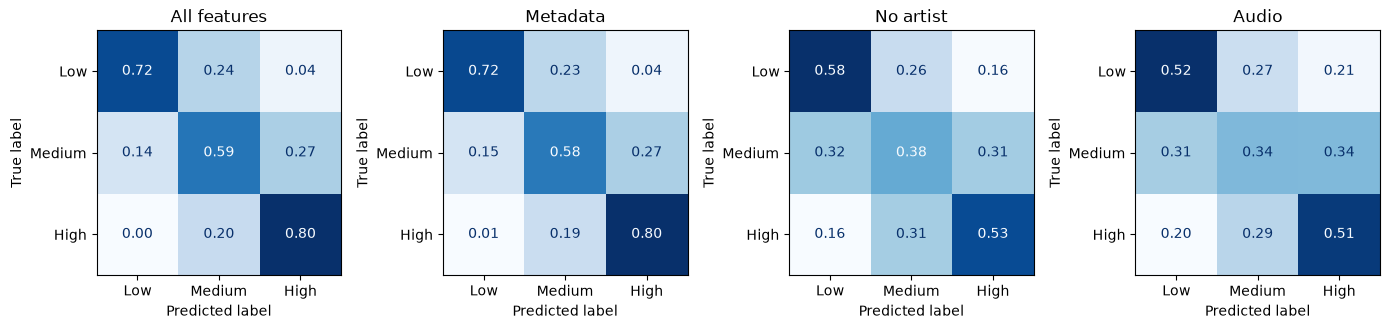

In [15]:
names = {"all": "All features", "r3_metadata": "Metadata", "r3_no_artist": "No artist", "r3_audio": "Audio"}
fig, ax = plt.subplots(1, 4, figsize=(14, 3.7))
for a, (key, title) in zip(ax, names.items()):
    d = pd.read_csv(out(f"mlpclf_val_predictions_{key}.csv"))
    ConfusionMatrixDisplay.from_predictions(d["y_true"], d["y_pred"], labels=CLASSES, normalize="true",
                                            values_format=".2f", cmap="Blues", ax=a, colorbar=False)
    a.set_title(title)
fig.tight_layout(); plt.show()

### 3.6 Regression MLP converted to classes (Appendix A.3)
*From `compare_r3.py` / `compare_by_feature_set.py`.* Regression predictions are cut at 40.5 and 60.5 and scored like a classifier. They tend towards the middle, so High is rarely predicted.

In [16]:
def to_class(x):                      # Low 0-40, Medium 41-60, High 61-100 (cut at 40.5 and 60.5)
    return pd.cut(pd.Series(x), [-np.inf, 40.5, 60.5, np.inf], labels=CLASSES)

def cls_metrics_labels(yc, pc):
    f1 = f1_score(yc, pc, labels=CLASSES, average=None, zero_division=0)
    return {"accuracy": accuracy_score(yc, pc), "macro_F1": f1.mean(),
            "Low_F1": f1[0], "Medium_F1": f1[1], "High_F1": f1[2],
            "High_recall": recall_score(yc, pc, labels=["High"], average=None, zero_division=0)[0]}

rows = []
for split, fname in [("validation", "mlp_val_predictions_{}.csv"), ("test", "mlp_test_predictions_{}.csv")]:
    for name in (["with_artist", "selected_3", "without_artist"] if split == "validation" else ["with_artist"]):
        d = pd.read_csv(out(fname.format(name)))
        rows.append({"split": split, "version": name, **cls_metrics_labels(to_class(d.y_true), to_class(d.y_pred))})
pd.DataFrame(rows)

,split,version,accuracy,macro_F1,Low_F1,Medium_F1,High_F1,High_recall
0,validation,with_artist,0.717,0.623,0.802,0.677,0.389,0.271
1,validation,selected_3,0.682,0.561,0.774,0.644,0.265,0.166
2,validation,without_artist,0.611,0.438,0.699,0.587,0.026,0.013
3,test,with_artist,0.719,0.620,0.805,0.681,0.376,0.258


## 4. Comparison with the R3 models
*From `compare_by_feature_set.py`, `compare_r3_test.py` and `make_report_figures.py`.*

This section actually runs: it reads the R3 tables in `results/` and the MLP prediction files and rebuilds the comparisons.

### 4.1 Validation, by feature set (Appendix A.4)

In [17]:
SETS = ["all", "metadata", "no_artist", "audio"]
REG_FILE = {"all": "with_artist", "no_artist": "r3_no_artist", "metadata": "r3_metadata", "audio": "r3_audio"}
CLF_FILE = {"all": "all", "no_artist": "r3_no_artist", "metadata": "r3_metadata", "audio": "r3_audio"}

reg3 = pd.read_csv(os.path.join(R3_DIR, "r3_reg_feature_groups.csv"))[["features", "model", "RMSE", "MAE", "R2"]]
cls3 = pd.read_csv(os.path.join(R3_DIR, "r3_cls_feature_groups.csv"))[
    ["features", "model", "accuracy", "macro_F1", "Low_F1", "Medium_F1", "High_F1", "High_recall"]]

reg_rows, cls_rows = [], []
for fs in SETS:
    d = pd.read_csv(out(f"mlp_val_predictions_{REG_FILE[fs]}.csv")); y, pr = d["y_true"].values, d["y_pred"].values
    reg_rows.append({"features": fs, "model": "MLP (regression)", "RMSE": mean_squared_error(y, pr) ** 0.5,
                     "MAE": mean_absolute_error(y, pr), "R2": r2_score(y, pr)})
    cls_rows.append({"features": fs, "model": "MLP regression, cut into classes", **cls_metrics_labels(to_class(y), to_class(pr))})
    d = pd.read_csv(out(f"mlpclf_val_predictions_{CLF_FILE[fs]}.csv"))
    cls_rows.append({"features": fs, "model": "MLP classifier",
                     **cls_metrics_labels(pd.Series(pd.Categorical(d["y_true"], CLASSES)),
                                          pd.Series(pd.Categorical(d["y_pred"], CLASSES)))})
reg_all = pd.concat([reg3, pd.DataFrame(reg_rows)], ignore_index=True)
cls_all = pd.concat([cls3, pd.DataFrame(cls_rows)], ignore_index=True)

def pivot(t, col):
    pv = t.pivot(index="model", columns="features", values=col).reindex(columns=SETS)
    return pv.sort_values("all", ascending=(col in ("RMSE", "MAE")))

for col in ["R2", "RMSE", "MAE"]:
    print(f"REGRESSION validation {col} by feature set"); display(pivot(reg_all, col))
for col in ["macro_F1", "accuracy", "High_recall"]:
    print(f"CLASSIFICATION validation {col} by feature set"); display(pivot(cls_all, col))

REGRESSION validation R2 by feature set


features,all,metadata,no_artist,audio
model,,,,
Random Forest,0.685,0.692,0.317,0.232
MLP (regression),0.664,0.656,0.298,0.224
Decision Tree,0.626,0.625,0.234,0.195
Ridge,0.595,0.562,0.154,0.144
k-NN,0.498,0.631,0.199,0.157


REGRESSION validation RMSE by feature set


features,all,metadata,no_artist,audio
model,,,,
Random Forest,9.395,9.297,13.834,14.667
MLP (regression),9.697,9.823,14.030,14.750
Decision Tree,10.240,10.253,14.655,15.023
Ridge,10.648,11.078,15.402,15.485
k-NN,11.865,10.170,14.981,15.374


REGRESSION validation MAE by feature set


features,all,metadata,no_artist,audio
model,,,,
Random Forest,7.231,7.070,10.936,11.726
MLP (regression),7.498,7.622,11.191,11.827
Decision Tree,7.863,7.901,11.638,12.001
Ridge,8.355,8.744,12.440,12.541
k-NN,9.397,7.826,12.003,12.336


... (2 outputs left out)

CLASSIFICATION validation accuracy by feature set


features,all,metadata,no_artist,audio
model,,,,
Random Forest,0.718,0.711,0.568,0.529
"MLP regression, cut into classes",0.717,0.716,0.567,0.541
Decision Tree,0.697,0.701,0.549,0.516
MLP classifier,0.675,0.674,0.492,0.452
Logistic Regression,0.654,0.646,0.385,0.358
Naive Bayes,0.651,0.645,0.462,0.499
k-NN,0.621,0.686,0.504,0.488


CLASSIFICATION validation High_recall by feature set


features,all,metadata,no_artist,audio
model,,,,
MLP classifier,0.800,0.799,0.531,0.510
Logistic Regression,0.758,0.755,0.627,0.643
Random Forest,0.583,0.672,0.176,0.135
Naive Bayes,0.440,0.479,0.024,0.000
Decision Tree,0.378,0.338,0.037,0.032
"MLP regression, cut into classes",0.271,0.236,0.003,0.000
k-NN,0.269,0.425,0.126,0.094


### 4.2 Figure A2: validation R² and macro-F1 by feature set
*From `make_report_figures.py`.* Saved as `r4_neural_networks/fig_r4_vs_r3_feature_sets_v2.png`.

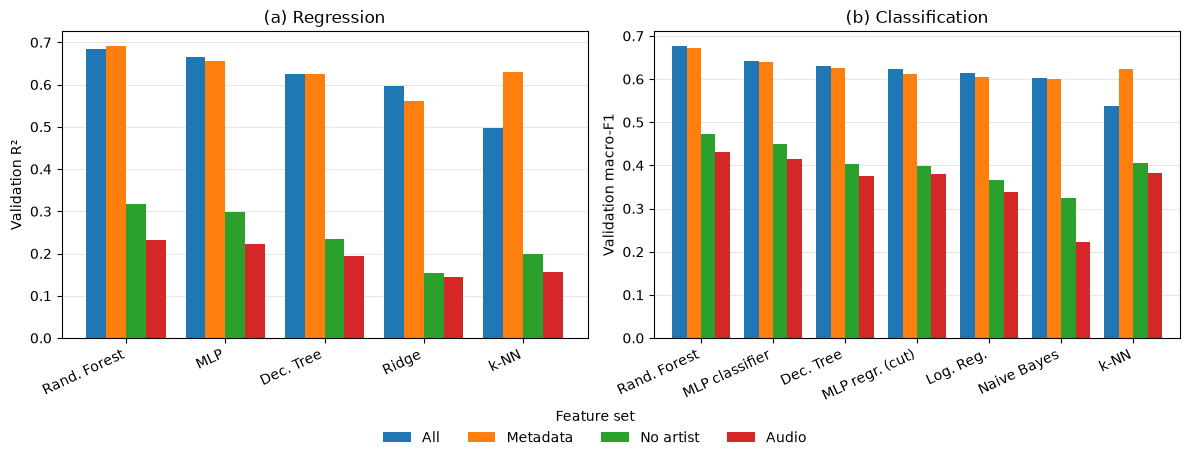

In [18]:
SET_LABEL = {"all": "All", "metadata": "Metadata", "no_artist": "No artist", "audio": "Audio"}
SHORT = {"MLP (regression)": "MLP", "MLP classifier": "MLP classifier",
         "MLP regression, cut into classes": "MLP regr. (cut)", "Logistic Regression": "Log. Reg.",
         "Random Forest": "Rand. Forest", "Decision Tree": "Dec. Tree", "Naive Bayes": "Naive Bayes"}

def panel(ax, t, col, ylabel, title):
    pv = t.pivot(index="model", columns="features", values=col).reindex(columns=SETS)
    pv = pv.sort_values("all", ascending=False)
    pv.index = [SHORT.get(m, m) for m in pv.index]
    pv.columns = [SET_LABEL[c] for c in pv.columns]
    pv.plot.bar(ax=ax, width=0.8, legend=False)
    ax.set_ylabel(ylabel); ax.set_title(title); ax.set_xlabel("")
    ax.set_xticklabels(pv.index, rotation=25, ha="right")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
panel(ax[0], reg_all, "R2", "Validation R²", "(a) Regression")
panel(ax[1], cls_all, "macro_F1", "Validation macro-F1", "(b) Classification")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, title="Feature set", loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

### 4.3 Table 1: test set, all features


In [19]:
REG_COLS = ["model", "RMSE", "MAE", "R2"]
CLS_COLS = ["model", "accuracy", "macro_F1", "Low_F1", "Medium_F1", "High_F1", "High_recall"]
r3_test_reg, r3_test_cls = os.path.join(R3_DIR, "r3_reg_TEST.csv"), os.path.join(R3_DIR, "r3_cls_TEST.csv")

if os.path.exists(r3_test_reg) and os.path.exists(r3_test_cls):
    print("Rebuilding Table 1 from results/r3_*_TEST.csv and the MLP test predictions")
    reg3t = pd.read_csv(r3_test_reg); reg3t = reg3t[[c for c in REG_COLS if c in reg3t.columns]]
    cls3t = pd.read_csv(r3_test_cls); cls3t = cls3t[[c for c in CLS_COLS if c in cls3t.columns]]
    d = pd.read_csv(out("mlp_test_predictions_with_artist.csv")); y, p = d["y_true"].values, d["y_pred"].values
    reg_mlp = pd.DataFrame([{"model": "MLP (regression)", "RMSE": mean_squared_error(y, p) ** 0.5,
                             "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}])
    cut = pd.DataFrame([{"model": "MLP regression, cut into classes", **cls_metrics_labels(to_class(y), to_class(p))}])
    d = pd.read_csv(out("mlpclf_test_predictions_all.csv"))
    clf = pd.DataFrame([{"model": "MLP classifier",
                         **cls_metrics_labels(pd.Series(pd.Categorical(d["y_true"], CLASSES)),
                                              pd.Series(pd.Categorical(d["y_pred"], CLASSES)))}])
    test_reg = pd.concat([reg3t, reg_mlp]).sort_values("RMSE")
    test_cls = pd.concat([cls3t, cut, clf]).sort_values("macro_F1", ascending=False)
else:
    print("results/r3_*_TEST.csv not found: showing the saved final_comparison_test_*.csv")
    test_reg = pd.read_csv(out("final_comparison_test_regression.csv"))
    test_cls = pd.read_csv(out("final_comparison_test_classification.csv"))
print("REGRESSION, test set, all features"); display(test_reg.reset_index(drop=True))
print("CLASSIFICATION, test set, all features"); display(test_cls.reset_index(drop=True))

Rebuilding Table 1 from results/r3_*_TEST.csv and the MLP test predictions
REGRESSION, test set, all features


,model,RMSE,MAE,R2
0,Random Forest,9.357,7.172,0.686
1,MLP (regression),9.621,7.465,0.668
2,Decision Tree,10.200,7.799,0.627
3,Ridge,10.591,8.325,0.598
4,k-NN,11.695,9.243,0.509
5,Baseline (train mean),16.699,13.412,-0.000


CLASSIFICATION, test set, all features


,model,accuracy,macro_F1,Low_F1,Medium_F1,High_F1,High_recall
0,Random Forest,0.721,0.678,0.797,0.681,0.554,0.568
1,MLP classifier,0.675,0.640,0.786,0.605,0.528,0.790
2,Decision Tree,0.696,0.624,0.780,0.653,0.439,0.364
3,"MLP regression, cut into classes",0.719,0.620,0.805,0.681,0.376,0.258
4,Logistic Regression,0.657,0.616,0.780,0.560,0.509,0.764
5,Naive Bayes,0.653,0.601,0.728,0.623,0.451,0.439
6,k-NN,0.615,0.528,0.714,0.564,0.307,0.255
7,Baseline (majority),0.500,0.222,0.666,0.000,0.000,0.000


## 5. Album covers (Appendix A.5)
These experiments need files that are too large for the repository: the raw SpotGenTrack CSVs, `MSD-I_dataset.tsv`, the `msdi-data/` folder (precomputed visual features) and the downloaded cover images. So their training code only runs when `RUN_TRAINING = True` and those files are present. The saved results are shown below each part.

### 5.1 Matching MSD-I to SpotGenTrack
*From `build_matched_features.py` and `download_covers.py`.* Matching uses cleaned artist and title, keeps only MSD-I tracks that match exactly one clean SpotGenTrack id, and attaches the precomputed visual features. Outputs: `matched_ids.csv`, `matched_visual_features.npz` and the `covers/` folder.

In [20]:
import re, ast, time, urllib.request

def norm(s):                                   # identical to the team's script
    s = str(s).lower()
    s = re.sub(r"\(.*?\)|\[.*?\]", "", s)
    s = re.sub(r"\s-\s.*$", "", s)
    s = re.sub(r"\b(feat|ft)\.?\b.*$", "", s)
    s = re.sub(r"[^a-z0-9 ]", "", s)
    return re.sub(r"\s+", " ", s).strip()

if RUN_TRAINING:
    # ---- build_matched_features.py ----
    m = pd.read_csv("msdi_spotgentrack_matches.csv")
    m["key"] = m["artist"].map(norm) + "|" + m["title"].map(norm)
    tracks = pd.read_csv("spotify_tracks.csv", usecols=["id", "name", "artists_id"])
    artists = (pd.read_csv("spotify_artists.csv", usecols=["id", "name"])
                 .drop_duplicates("id").rename(columns={"id": "artist_id", "name": "artist"}))
    tracks["artist_id"] = tracks["artists_id"].apply(lambda x: ast.literal_eval(x)[0])
    sp = tracks.merge(artists, on="artist_id", how="left")
    sp["key"] = sp["artist"].map(norm) + "|" + sp["name"].map(norm)
    pairs = m[["msd_track_id", "key"]].drop_duplicates().merge(sp[["key", "id"]].drop_duplicates(), on="key")
    pairs = pairs.merge(pd.read_csv("spotgentrack_clean.csv", usecols=["id", "split", "popularity"]), on="id", how="inner")
    n_ids = pairs.groupby("msd_track_id")["id"].nunique()
    final = (pairs[pairs["msd_track_id"].isin(n_ids[n_ids == 1].index)]
             .drop(columns="key").drop_duplicates().reset_index(drop=True))
    final["split"] = final["split"].replace({"validation": "val"})
    base = "msdi-data/"
    ids, vis, mm = [], [], []
    for s in ["train", "val", "test"]:
        idx = pd.read_csv(f"{base}splits/items_index_{s}_MSD-I.tsv", sep="\t", header=None)[0]
        xv = np.load(f"{base}train_data/X_{s}_visual_MSD-I.npy")
        xm = np.load(f"{base}train_data/X_{s}_mm-visual_MSD-I.npy")
        assert len(idx) == len(xv) == len(xm), f"{s}: index/feature size mismatch"
        ids.append(idx); vis.append(xv); mm.append(xm)
    all_ids = pd.concat(ids, ignore_index=True); all_vis, all_mm = np.vstack(vis), np.vstack(mm)
    pos = pd.Series(np.arange(len(all_ids)), index=all_ids.values)
    rows_ = pos.reindex(final["msd_track_id"])
    final = final[rows_.notna().values].reset_index(drop=True)
    rows_ = rows_.dropna().astype(int).values
    final.to_csv(out("matched_ids.csv"), index=False)
    np.savez_compressed(out("matched_visual_features.npz"),
                        id=final["id"].astype(str).values, msd_track_id=final["msd_track_id"].astype(str).values,
                        split=final["split"].astype(str).values, popularity=final["popularity"].values,
                        X_visual=all_vis[rows_], X_mm=all_mm[rows_])
    # ---- download_covers.py ----
    msdi_urls = pd.read_csv("MSD-I_dataset.tsv", sep="\t").set_index("msd_track_id")
    os.makedirs("covers", exist_ok=True)
    failed = []
    for tid in final["msd_track_id"]:
        dest = f"covers/{tid}.jpg"
        if os.path.exists(dest): continue
        try:
            req = urllib.request.Request(msdi_urls.loc[tid, "image_url"], headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=15) as r, open(dest, "wb") as f: f.write(r.read())
            time.sleep(0.2)
        except Exception as e:
            failed.append((tid, str(e)))
    print("downloaded:", len(final) - len(failed), "| failed:", len(failed))

# saved result of the matching
matched = pd.read_csv(out("matched_ids.csv"))
z = np.load(out("matched_visual_features.npz"))
print("matched tracks used:", len(matched), "| visual feature vector size:", z["X_visual"].shape[1])
matched["split"].value_counts().reindex(["train", "val", "test"]).to_frame("tracks")

matched tracks used: 394 | visual feature vector size: 2048


,tracks
split,
train,276
val,60
test,58


### 5.2 (a) MLP with the precomputed MSD-I visual features
*From `cover_features_keras.py`.* Each 2048-value visual vector is standardised and reduced with PCA (fitted on training rows only) to 8, 16 or 32 components and added to the tabular features in a small Keras MLP (Dense 32, dropout 0.3, L2 0.001). Three seeds. Evaluated on the team split and in a 5-fold CV that keeps each artist in one fold.

In [21]:
def cover_metrics(a, b): return {"MAE": mean_absolute_error(a, b), "RMSE": rmse(a, b), "R2": r2_score(a, b)}

def artist_folds(g, n_folds, seed):
    ug = np.array(sorted(set(g))); np.random.RandomState(seed).shuffle(ug)
    fo = {a: i % n_folds for i, a in enumerate(ug)}
    return np.array([fo[a] for a in g])

def inner_split(pool, groups, seed):
    gp = groups[pool]; ug = np.array(sorted(set(gp))); np.random.RandomState(seed).shuffle(ug)
    vg = set(ug[: max(1, int(0.2 * len(ug)))]); isv = np.array([a in vg for a in gp])
    return pool[~isv], pool[isv]

def summarize(res):
    rows = []
    for name, lst in res.items():
        d = pd.DataFrame(lst)
        if len(d) > 1:
            rows.append({"model": name, **{c: f"{d[c].mean():.3f} ± {d[c].std():.3f}" for c in d.columns}})
        else:
            rows.append({"model": name, **{c: f"{d[c].iloc[0]:.3f}" for c in d.columns}})
    return pd.DataFrame(rows)

def load_cover_data(version):
    """Matched tracks, their tabular features (with or without artist features), target and artist groups."""
    mt = pd.read_csv(out("matched_ids.csv"), usecols=["id", "msd_track_id", "split"])
    msdi = pd.read_csv("MSD-I_dataset.tsv", sep="\t")[["msd_track_id", "msd_artist_id"]]
    mt = mt.merge(msdi, on="msd_track_id", how="left")
    clean = pd.read_csv("spotgentrack_clean.csv"); clean["split"] = clean["split"].replace({"validation": "val"})
    fcols = [c for c in clean.columns if c not in DROP]
    if version == "without_artist":
        fcols = [c for c in fcols if c not in ("artist_popularity", "log_followers")]
    ccols = [c for c in fcols if clean[c].nunique() > 2]
    cl = clean.set_index("id").loc[mt["id"]]
    assert (cl["split"].values == mt["split"].values).all(), "splits differ: re-run the matching"
    return (mt, cl[fcols].astype("float32").reset_index(drop=True), ccols,
            cl["popularity"].values.astype("float32"), mt["msd_artist_id"].values)

def run_cover_features(version, SEEDS=(0, 1, 2), KS=(8, 16, 32)):
    mt, T, ccols, y, groups = load_cover_data(version)
    Xv = np.load(out("matched_visual_features.npz"))["X_visual"]

    def build(kind, k, tr, others):
        sc = StandardScaler().fit(T.loc[tr, ccols])
        def tab(ix):
            X = T.loc[ix].copy(); X[ccols] = sc.transform(X[ccols]); return X.values.astype("float32")
        ptr, po = [tab(tr)], [[tab(o)] for o in others]
        if kind == "both":
            s1 = StandardScaler().fit(Xv[tr])
            pca = PCA(n_components=k, random_state=0).fit(s1.transform(Xv[tr]))
            s2 = StandardScaler().fit(pca.transform(s1.transform(Xv[tr])))
            def img(ix): return s2.transform(pca.transform(s1.transform(Xv[ix]))).astype("float32")
            ptr.append(img(tr))
            for p, o in zip(po, others): p.append(img(o))
        return np.hstack(ptr), [np.hstack(p) for p in po]

    def fit_predict(Xtr, ytr, Xva, yva_, Xte, seed):
        keras.utils.set_random_seed(seed)
        mu, sd = float(ytr.mean()), float(ytr.std())
        model = keras.Sequential([keras.Input(shape=(Xtr.shape[1],)),
            layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(1e-3)),
            layers.Dropout(0.3), layers.Dense(1)])
        model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse",
                      metrics=[keras.metrics.RootMeanSquaredError(name="rmse")])
        es = keras.callbacks.EarlyStopping(monitor="val_rmse", mode="min", patience=30, restore_best_weights=True)
        model.fit(Xtr, (ytr - mu) / sd, validation_data=(Xva, (yva_ - mu) / sd),
                  epochs=300, batch_size=32, callbacks=[es], verbose=0)
        p = model.predict(Xte, verbose=0).ravel() * sd + mu
        keras.backend.clear_session(); return p

    CONFIGS = [("mean_baseline", None, None), ("tabular", "tab", None)] + [(f"tabular+image_k{k}", "both", k) for k in KS]
    def run_configs(tr, va, te, seed):
        o = {}
        for name, kind, k in CONFIGS:
            if kind is None: o[name] = np.full(len(te), y[tr].mean())
            else:
                Xtr, (Xva, Xte) = build(kind, k, tr, [va, te])
                o[name] = fit_predict(Xtr, y[tr], Xva, y[va], Xte, seed)
        return o

    tr, va, te = (np.where(mt["split"] == s)[0] for s in ["train", "val", "test"])
    res = {n: [] for n, _, _ in CONFIGS}
    for s in SEEDS:
        for name, p in run_configs(tr, va, te, s).items(): res[name].append(cover_metrics(y[te], p))
    summarize(res).to_csv(out(f"keras_cover_results_team_split_{version}.csv"), index=False)
    res_cv = {n: [] for n, _, _ in CONFIGS}
    for s in SEEDS:
        f = artist_folds(groups, 5, s); oof = {n: np.zeros(len(mt)) for n, _, _ in CONFIGS}
        for k in range(5):
            te_k = np.where(f == k)[0]; pool = np.where(f != k)[0]
            tr_k, va_k = inner_split(pool, groups, s)
            for name, p in run_configs(tr_k, va_k, te_k, s).items(): oof[name][te_k] = p
        for name in oof: res_cv[name].append(cover_metrics(y, oof[name]))
    summarize(res_cv).to_csv(out(f"keras_cover_results_grouped_cv_{version}.csv"), index=False)

if RUN_TRAINING:
    for version in ["with_artist", "without_artist"]:
        run_cover_features(version)

for version in ["with_artist", "without_artist"]:
    for ev in ["team_split", "grouped_cv"]:
        print(f"{ev}, {version}")
        display(pd.read_csv(out(f"keras_cover_results_{ev}_{version}.csv")))

team_split, with_artist


,model,MAE,RMSE,R2
0,mean_baseline,12.257 ± 0.000,15.008 ± 0.000,-0.016 ± 0.000
1,tabular,10.446 ± 0.877,13.523 ± 0.738,0.173 ± 0.091
2,tabular+image_k8,11.018 ± 0.520,13.884 ± 0.307,0.130 ± 0.039
3,tabular+image_k16,10.707 ± 0.192,13.525 ± 0.248,0.174 ± 0.030
4,tabular+image_k32,11.188 ± 0.196,14.052 ± 0.342,0.109 ± 0.044


grouped_cv, with_artist


,model,MAE,RMSE,R2
0,mean_baseline,10.355 ± 0.024,12.646 ± 0.037,-0.012 ± 0.006
1,tabular,9.081 ± 0.331,11.481 ± 0.289,0.166 ± 0.042
2,tabular+image_k8,9.301 ± 0.226,11.620 ± 0.202,0.146 ± 0.030
3,tabular+image_k16,9.529 ± 0.257,11.780 ± 0.202,0.122 ± 0.030
4,tabular+image_k32,9.802 ± 0.138,12.056 ± 0.166,0.080 ± 0.025


team_split, without_artist


,model,MAE,RMSE,R2
0,mean_baseline,12.257 ± 0.000,15.008 ± 0.000,-0.016 ± 0.000
1,tabular,11.985 ± 0.356,14.846 ± 0.301,0.005 ± 0.041
2,tabular+image_k8,12.340 ± 0.505,15.202 ± 0.471,-0.043 ± 0.064
3,tabular+image_k16,12.315 ± 0.554,14.947 ± 0.222,-0.008 ± 0.030
4,tabular+image_k32,12.561 ± 0.945,15.081 ± 0.615,-0.027 ± 0.085


grouped_cv, without_artist


,model,MAE,RMSE,R2
0,mean_baseline,10.355 ± 0.024,12.646 ± 0.037,-0.012 ± 0.006
1,tabular,10.479 ± 0.035,12.966 ± 0.034,-0.064 ± 0.006
2,tabular+image_k8,10.481 ± 0.149,13.025 ± 0.238,-0.073 ± 0.039
3,tabular+image_k16,10.726 ± 0.110,13.235 ± 0.149,-0.108 ± 0.025
4,tabular+image_k32,10.849 ± 0.192,13.360 ± 0.276,-0.130 ± 0.047


### 5.3 (b) CNN on the raw covers (MobileNetV2)
*From `cnn_covers_keras.py`.* MobileNetV2 pretrained on ImageNet, 128×128 covers, random horizontal flips, global average pooling, dropout 0.3, Dense 16 (L2 0.001), Dense 32 and a linear output. Combined models concatenate the tabular features before Dense 32.

Training has two stages: (1) the CNN is frozen and only the new layers train (Adam 0.001, up to 40 epochs, patience 8); (2) the top 20 layers are fine-tuned with BatchNorm frozen (learning rate 0.00001, up to 20 epochs, patience 6). Batch size 32, early stopping on validation RMSE, one seed.

In [22]:
IMG, WEIGHTS, UNFREEZE = 128, "imagenet", 20

def load_images(paths):
    from PIL import Image
    return np.stack([np.asarray(Image.open(p).convert("RGB").resize((IMG, IMG)), dtype="float32") for p in paths])

def cnn_build_model(n_tab, use_tab):
    base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights=WEIGHTS)
    base.trainable = False                                # stage 1: pretrained CNN frozen
    img_in = keras.Input(shape=(IMG, IMG, 3))
    x = layers.RandomFlip("horizontal")(img_in)           # augmentation, only active in training
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)     # MobileNetV2 expects inputs in [-1, 1]
    x = base(x, training=False)                           # keeps BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l2(1e-3))(x)
    inputs = [img_in]
    if use_tab:
        tab_in = keras.Input(shape=(n_tab,)); x = layers.Concatenate()([x, tab_in]); inputs.append(tab_in)
    x = layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(1e-3))(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(inputs, layers.Dense(1)(x)), base

def fit_predict_cnn(Itr, Ttr, ytr, Iva, Tva, yva_, Ite, Tte, seed, use_tab):
    keras.utils.set_random_seed(seed)
    mu, sd = float(ytr.mean()), float(ytr.std())
    model, base = cnn_build_model(Ttr.shape[1] if use_tab else 0, use_tab)
    pack = (lambda I, T: [I, T]) if use_tab else (lambda I, T: I)
    def run(lr, epochs, patience):
        model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse",
                      metrics=[keras.metrics.RootMeanSquaredError(name="rmse")])
        es = keras.callbacks.EarlyStopping(monitor="val_rmse", mode="min", patience=patience, restore_best_weights=True)
        model.fit(pack(Itr, Ttr), (ytr - mu) / sd, validation_data=(pack(Iva, Tva), (yva_ - mu) / sd),
                  epochs=epochs, batch_size=32, callbacks=[es], verbose=0)
    run(1e-3, 40, 8)                                      # stage 1: train the new layers only
    base.trainable = True                                 # stage 2: fine-tune the top CNN layers
    for layer in base.layers[:-UNFREEZE]: layer.trainable = False
    for layer in base.layers[-UNFREEZE:]: layer.trainable = not isinstance(layer, layers.BatchNormalization)
    run(1e-5, 20, 6)                                      # small learning rate for fine-tuning
    p = model.predict(pack(Ite, Tte), batch_size=64, verbose=0).ravel() * sd + mu
    keras.backend.clear_session(); return p

def fit_predict_mlp_small(Xtr, ytr, Xva, yva_, Xte, seed):
    """Plain Keras MLP on the tabular features (same data, for a fair comparison)."""
    keras.utils.set_random_seed(seed)
    mu, sd = float(ytr.mean()), float(ytr.std())
    model = keras.Sequential([keras.Input(shape=(Xtr.shape[1],)),
        layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(1e-3)),
        layers.Dropout(0.3), layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse",
                  metrics=[keras.metrics.RootMeanSquaredError(name="rmse")])
    es = keras.callbacks.EarlyStopping(monitor="val_rmse", mode="min", patience=30, restore_best_weights=True)
    model.fit(Xtr, (ytr - mu) / sd, validation_data=(Xva, (yva_ - mu) / sd),
              epochs=300, batch_size=32, callbacks=[es], verbose=0)
    p = model.predict(Xte, verbose=0).ravel() * sd + mu
    keras.backend.clear_session(); return p

def run_cnn(version, SEEDS=(0,)):
    mt, T, ccols, y, groups = load_cover_data(version)
    paths = [f"covers/{t}.jpg" for t in mt["msd_track_id"]]
    missing = [p for p in paths if not os.path.exists(p)]
    assert not missing, f"{len(missing)} covers missing: run the download step first"
    imgs = load_images(paths)
    def tab_prep(tr, others):                              # scaler fitted on the training rows only
        sc = StandardScaler().fit(T.loc[tr, ccols])
        def tab(ix):
            X = T.loc[ix].copy(); X[ccols] = sc.transform(X[ccols]); return X.values.astype("float32")
        return tab(tr), [tab(o) for o in others]
    CONFIGS = [("mean_baseline", "mean"), ("tabular_mlp", "mlp")]
    if version == "with_artist": CONFIGS.append(("cnn_image_only", "cnn"))
    CONFIGS.append(("tabular+cnn", "cnn+tab"))
    def run_configs(tr, va, te, seed):
        Xtr, (Xva, Xte) = tab_prep(tr, [va, te]); o = {}
        for name, kind in CONFIGS:
            if kind == "mean":  o[name] = np.full(len(te), y[tr].mean())
            elif kind == "mlp": o[name] = fit_predict_mlp_small(Xtr, y[tr], Xva, y[va], Xte, seed)
            elif kind == "cnn": o[name] = fit_predict_cnn(imgs[tr], None, y[tr], imgs[va], None, y[va], imgs[te], None, seed, False)
            else:               o[name] = fit_predict_cnn(imgs[tr], Xtr, y[tr], imgs[va], Xva, y[va], imgs[te], Xte, seed, True)
        return o
    tr, va, te = (np.where(mt["split"] == s)[0] for s in ["train", "val", "test"])
    res = {n: [] for n, _ in CONFIGS}
    for s in SEEDS:
        for name, p in run_configs(tr, va, te, s).items(): res[name].append(cover_metrics(y[te], p))
    summarize(res).to_csv(out(f"keras_cnn_results_team_split_{version}.csv"), index=False)
    res_cv = {n: [] for n, _ in CONFIGS}
    for s in SEEDS:
        f = artist_folds(groups, 5, s); oof = {n: np.zeros(len(mt)) for n, _ in CONFIGS}
        for k in range(5):
            te_k = np.where(f == k)[0]; pool = np.where(f != k)[0]
            tr_k, va_k = inner_split(pool, groups, s)
            for name, p in run_configs(tr_k, va_k, te_k, s).items(): oof[name][te_k] = p
        for name in oof: res_cv[name].append(cover_metrics(y, oof[name]))
    summarize(res_cv).to_csv(out(f"keras_cnn_results_grouped_cv_{version}.csv"), index=False)

if RUN_TRAINING:
    for version in ["with_artist", "without_artist"]:
        run_cnn(version)

for version in ["with_artist", "without_artist"]:
    for ev in ["team_split", "grouped_cv"]:
        print(f"{ev}, {version}")
        display(pd.read_csv(out(f"keras_cnn_results_{ev}_{version}.csv")))

team_split, with_artist


,model,MAE,RMSE,R2
0,mean_baseline,12.257,15.008,-0.016
1,tabular_mlp,10.038,12.990,0.239
2,cnn_image_only,11.775,14.184,0.092
3,tabular+cnn,9.773,12.578,0.286


grouped_cv, with_artist


,model,MAE,RMSE,R2
0,mean_baseline,10.328,12.614,-0.007
1,tabular_mlp,8.770,11.232,0.202
2,cnn_image_only,10.819,13.163,-0.096
3,tabular+cnn,10.130,12.541,0.005


team_split, without_artist


,model,MAE,RMSE,R2
0,mean_baseline,12.257,15.008,-0.016
1,tabular_mlp,11.776,14.609,0.037
2,tabular+cnn,12.518,15.202,-0.043


grouped_cv, without_artist


,model,MAE,RMSE,R2
0,mean_baseline,10.328,12.614,-0.007
1,tabular_mlp,10.517,12.979,-0.066
2,tabular+cnn,11.158,13.659,-0.180
